# 04.02 Document Preprocessing

**Phase 04 — Document Processing & OCR**  
**Objective:** Load validated images and PDFs, render PDF pages via `pypdfium2`, apply EXIF orientation correction, bounded resizing, skew correction, denoising, CLAHE contrast enhancement, and image quality scoring — saving reproducible outputs under `data/interim/document_processing/preprocessed_docs/` without ever overwriting raw documents.


### 1. Environment Setup & Preprocessing Configuration


In [1]:
import os
import sys
import json
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

def _find_root(p: Path = Path.cwd()) -> Path:
    for parent in [p.resolve(), *p.resolve().parents]:
        if (parent / 'data').exists() and (parent / 'experiments').exists():
            return parent
    return p.resolve()

PROJECT_ROOT = _find_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.document_processing import DocumentProcessingPaths
paths = DocumentProcessingPaths(PROJECT_ROOT)

OUTPUT_DIR = paths.interim_doc_proc / 'preprocessed_docs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREP_LOG_CSV = OUTPUT_DIR / 'preprocessing_log.csv'

PREPROCESSING_CONFIG = {
    'max_long_edge_px': 2000,
    'pdf_render_dpi': 200,
    'clahe_clip_limit': 2.0,
    'clahe_tile_grid': (8, 8),
    'denoise_h': 7,
    'max_skew_deg': 15.0,
    'min_blur_var_threshold': 40.0,
    'max_batch_samples': 50,  # Set to None to preprocess the entire inventory
    'overwrite_existing': False,
}

print(f"Project Root    : {paths.root}")
print(f"Inventory CSV   : {paths.doc_inventory_manifest} (exists={paths.doc_inventory_manifest.exists()})")
print(f"Output Dir      : {OUTPUT_DIR}")


Project Root    : C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2
Inventory CSV   : C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\document_processing\document_inventory_manifest.csv (exists=True)
Output Dir      : C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\document_processing\preprocessed_docs


### 2. Image/PDF Loading, Orientation, Deskewing, Enhancement & Quality Checks


In [2]:
def load_document_pages(file_path: Path, pdf_dpi: int = 200) -> list:
    """Loads an image (with EXIF orientation correction) or renders PDF pages to BGR numpy arrays."""
    ext = file_path.suffix.lower()
    pages = []
    if ext == '.pdf':
        import pypdfium2 as pdfium
        pdf = pdfium.PdfDocument(str(file_path))
        scale = pdf_dpi / 72.0
        for idx in range(len(pdf)):
            pil_page = pdf[idx].render(scale=scale).to_pil().convert('RGB')
            pages.append((idx + 1, cv2.cvtColor(np.array(pil_page), cv2.COLOR_RGB2BGR)))
        pdf.close()
    else:
        with Image.open(file_path) as pil_img:
            pil_img = ImageOps.exif_transpose(pil_img).convert('RGB')
            pages.append((1, cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)))
    return pages

def resize_bounded(image: np.ndarray, max_long_edge: int = 2000) -> np.ndarray:
    h, w = image.shape[:2]
    long_edge = max(h, w)
    if long_edge <= max_long_edge:
        return image
    scale = max_long_edge / float(long_edge)
    return cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)

def estimate_skew_angle(image: np.ndarray, max_skew: float = 15.0) -> float:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)[1]
    coords = np.column_stack(np.where(thresh > 0))
    if len(coords) < 100:
        return 0.0
    angle = cv2.minAreaRect(coords)[-1]
    if angle < -45:
        angle = -(90 + angle)
    elif angle > 45:
        angle = 90 - angle
    else:
        angle = -angle
    if abs(angle) > max_skew:
        return 0.0
    return round(float(angle), 2)

def deskew_image(image: np.ndarray, angle: float) -> np.ndarray:
    if abs(angle) < 0.3:
        return image
    h, w = image.shape[:2]
    M = cv2.getRotationMatrix2D((w // 2, h // 2), angle, 1.0)
    return cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

def enhance_document_bgr(image: np.ndarray, cfg: dict = PREPROCESSING_CONFIG) -> np.ndarray:
    """Preserves color cues for OCR/stamps while applying gentle LAB-L CLAHE and denoising."""
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l_ch, a_ch, b_ch = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=cfg['clahe_clip_limit'], tileGridSize=cfg['clahe_tile_grid'])
    l_enh = clahe.apply(l_ch)
    l_den = cv2.fastNlMeansDenoising(l_enh, None, h=cfg['denoise_h'], templateWindowSize=7, searchWindowSize=21)
    merged = cv2.merge([l_den, a_ch, b_ch])
    return cv2.cvtColor(merged, cv2.COLOR_LAB2BGR)

def compute_quality_metrics(image: np.ndarray) -> dict:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    blur_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    contrast = float(gray.std())
    brightness = float(gray.mean())
    quality_flag = 'OK'
    if blur_var < PREPROCESSING_CONFIG['min_blur_var_threshold']:
        quality_flag = 'BLURRY'
    elif brightness < 45.0:
        quality_flag = 'UNDEREXPOSED'
    elif brightness > 240.0:
        quality_flag = 'OVEREXPOSED'
    return {
        'blur_laplacian_var': round(blur_var, 2),
        'contrast_std': round(contrast, 2),
        'mean_brightness': round(brightness, 2),
        'quality_flag': quality_flag,
    }

print("[OK] Document preprocessing & quality verification functions ready.")


[OK] Document preprocessing & quality verification functions ready.


### 3. Execute Batch Preprocessing & Export Log


Preprocessed 50 document pages -> C:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\document_processing\preprocessed_docs\preprocessing_log.csv


,document_id,original_file,document_category,page_number,original_dimensions,processed_dimensions,detected_skew_deg,blur_laplacian_var,contrast_std,mean_brightness,quality_flag,processed_output_path,status
0,DOC_FD117F16,ind_p_001.jpeg,certificate_of_indigency,1,3024x4032,1500x2000,0.0,593.72,51.70,157.34,OK,data/interim/document_processing/preprocessed_...,SUCCESS
1,DOC_C30FBF12,ind_p_002.jpeg,certificate_of_indigency,1,3024x4032,1500x2000,-0.0,502.01,59.46,161.15,OK,data/interim/document_processing/preprocessed_...,SUCCESS
2,DOC_5279B906,ind_p_003.jpg,certificate_of_indigency,1,2296x4080,1125x2000,0.0,802.54,55.99,123.36,OK,data/interim/document_processing/preprocessed_...,SUCCESS
3,DOC_C600B286,ind_p_004.jpg,certificate_of_indigency,1,2296x4080,1125x2000,0.0,341.60,42.95,119.92,OK,data/interim/document_processing/preprocessed_...,SUCCESS
4,DOC_DC782CBC,ind_p_005.jpeg,certificate_of_indigency,1,3024x4032,1500x2000,0.0,1332.69,57.00,162.66,OK,data/interim/document_processing/preprocessed_...,SUCCESS
5,DOC_BB34E65F,ind_p_006.jpeg,certificate_of_indigency,1,3024x4032,1500x2000,0.0,2291.35,64.03,136.21,OK,data/interim/document_processing/preprocessed_...,SUCCESS
6,DOC_CC019FA9,ind_p_007.jpeg,certificate_of_indigency,1,3024x4032,1500x2000,0.0,491.78,49.88,167.27,OK,data/interim/document_processing/preprocessed_...,SUCCESS
7,DOC_AABE13AE,ind_p_008.jpeg,certificate_of_indigency,1,3024x4032,1500x2000,0.0,426.93,45.59,166.08,OK,data/interim/document_processing/preprocessed_...,SUCCESS
8,DOC_5FDCC067,ind_p_009.jpg,certificate_of_indigency,1,2296x4080,1125x2000,0.0,945.86,47.92,119.94,OK,data/interim/document_processing/preprocessed_...,SUCCESS
9,DOC_372639FA,ind_p_010.jpg,certificate_of_indigency,1,2296x4080,1125x2000,0.0,1471.53,50.37,128.06,OK,data/interim/document_processing/preprocessed_...,SUCCESS


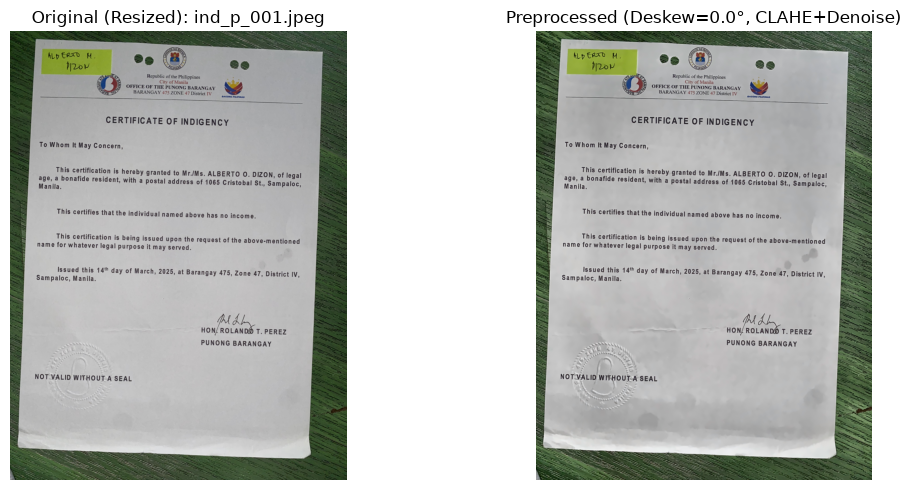

In [3]:
if not paths.doc_inventory_manifest.exists():
    raise FileNotFoundError(f"Run Notebook 01 first to generate {paths.doc_inventory_manifest}")

df_inv = pd.read_csv(paths.doc_inventory_manifest)
if 'is_readable' in df_inv.columns:
    df_inv = df_inv[df_inv['is_readable'] == True].copy()

limit = PREPROCESSING_CONFIG['max_batch_samples']
df_to_process = df_inv.head(limit) if limit is not None else df_inv

log_records = []
sample_vis_pair = None

for _, row in df_to_process.iterrows():
    src_path = paths.resolve_sample_path(str(row['relative_path']))
    if not src_path.exists():
        continue
    pages = load_document_pages(src_path, pdf_dpi=PREPROCESSING_CONFIG['pdf_render_dpi'])
    for page_num, bgr in pages:
        orig_h, orig_w = bgr.shape[:2]
        out_name = f"prep_{src_path.stem}_p{page_num:02d}.png"
        out_path = OUTPUT_DIR / out_name

        resized = resize_bounded(bgr, PREPROCESSING_CONFIG['max_long_edge_px'])
        angle = estimate_skew_angle(resized, PREPROCESSING_CONFIG['max_skew_deg'])
        deskewed = deskew_image(resized, angle)
        enhanced = enhance_document_bgr(deskewed, PREPROCESSING_CONFIG)
        q_metrics = compute_quality_metrics(enhanced)

        if PREPROCESSING_CONFIG['overwrite_existing'] or not out_path.exists():
            cv2.imwrite(str(out_path), enhanced)

        if sample_vis_pair is None:
            sample_vis_pair = (src_path.name, resized, enhanced, angle)

        log_records.append({
            'document_id': row.get('document_id', src_path.stem),
            'original_file': src_path.name,
            'document_category': row.get('document_category', 'unknown'),
            'page_number': page_num,
            'original_dimensions': f"{orig_w}x{orig_h}",
            'processed_dimensions': f"{enhanced.shape[1]}x{enhanced.shape[0]}",
            'detected_skew_deg': angle,
            **q_metrics,
            'processed_output_path': str(out_path.relative_to(paths.root)).replace('\\', '/'),
            'status': 'SUCCESS',
        })

df_prep_log = pd.DataFrame(log_records)
df_prep_log.to_csv(PREP_LOG_CSV, index=False, encoding='utf-8')
print(f"Preprocessed {len(df_prep_log):,} document pages -> {PREP_LOG_CSV}")
display(df_prep_log.head(10))

if sample_vis_pair is not None:
    fname, orig_bgr, enh_bgr, ang = sample_vis_pair
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f'Original (Resized): {fname}')
    axes[0].axis('off')
    axes[1].imshow(cv2.cvtColor(enh_bgr, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f'Preprocessed (Deskew={ang}°, CLAHE+Denoise)')
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()
